<div align="center">
    <img src="https://www.sharif.ir/documents/20124/0/logo-fa-IR.png/4d9b72bc-494b-ed5a-d3bb-e7dfd319aec8?t=1609608338755" alt="Logo" width="200">
    <p><b>HW2 @ Deep Learning Course, Dr. Soleymani</b></p>
    <p><b>Desinged by Mohammad Amanlou</b></p>
</div>

---



# تمرین CNN — «آزمایشگاه حال‌سنجی ایموجی‌ها»

در این پروژه قرار است یک **CNN از صفر** برای تشخیص حالت چهره‌ی ایموجی‌ها بسازیم.  
ایده‌ی پروژه این است که یک ربات بامزه باید از روی تصویر ایموجی‌ها تشخیص بدهد که حال آن‌ها چیست:

- `happy`
- `sad`
- `angry`
- `surprised`
- `sleepy`

## داستان پروژه
در شهر ایموجی‌ها، یک ربات کوچک وظیفه دارد پیام‌های تصویری را مرتب‌سازی کند.  
اما ایموجی‌ها همیشه تمیز و واضح نیستند: گاهی کمی چرخیده‌اند، گاهی نویز دارند، گاهی جابه‌جا شده‌اند.  
هدف شما این است که یک مدل CNN طراحی کنید که در چنین شرایطی هم بتواند حالت چهره را درست تشخیص دهد.

## بعد از انجام این نوت‌بوک باید بتوانید:
1. یک دیتاست تصویری را بسازید یا بارگذاری کنید.
2. روی داده‌ها **EDA** ساده انجام دهید.
3. **Data Augmentation** مناسب برای مسئله‌ی تصویری انتخاب کنید.
4. یک **CNN پایه** را از صفر پیاده‌سازی و آموزش دهید.
5. با استفاده از **loss curve**، **accuracy**، **macro F1** و **confusion matrix** مدل را تحلیل کنید.
6. خطاهای مدل را بررسی کنید و یک نسخه‌ی بهبود‌یافته از مدل ارائه دهید.

## بخش ۰ — کتابخانه‌ها و تنظیمات اولیه

### خروجی مورد انتظار
- چاپ دستگاه اجرا
- چاپ نام کلاس‌ها

In [1]:
import math
import random
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image, ImageDraw, ImageFilter, ImageOps, ImageEnhance

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE = 64
BATCH_SIZE = 64
NUM_CLASSES = 5
CLASS_NAMES = ["happy", "sad", "angry", "surprised", "sleepy"]

# TODO:
print("Device:", device)
print("Class names:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Device: cpu
Class names: ['happy', 'sad', 'angry', 'surprised', 'sleepy']
Number of classes: 5
Image size: 64
Batch size: 64


## بخش ۱ — ساخت دیتاست مصنوعی ایموجی‌ها

In [2]:
def _jitter(rng, low, high):
    return rng.randint(low, high)

def add_soft_noise(img, rng, amount=35):
    arr = np.array(img).astype(np.int16)
    noise = rng.normalvariate(0, 1)
    gaussian = np.random.default_rng(rng.randint(0, 10_000)).normal(0, amount, size=arr.shape)
    arr = np.clip(arr + gaussian, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

def draw_emoji(label, img_size=64, seed=0, hard_mode=False):
    rng = random.Random(seed)

    bg_color = (
        245 + _jitter(rng, -8, 8),
        245 + _jitter(rng, -8, 8),
        250 + _jitter(rng, -8, 5),
    )
    img = Image.new("RGB", (img_size, img_size), bg_color)
    draw = ImageDraw.Draw(img)

    # background dots
    for _ in range(40 if not hard_mode else 70):
        x = _jitter(rng, 0, img_size - 1)
        y = _jitter(rng, 0, img_size - 1)
        r = _jitter(rng, 1, 2)
        c = 235 + _jitter(rng, -18, 12)
        draw.ellipse((x-r, y-r, x+r, y+r), fill=(c, c, c + _jitter(rng, -5, 5)))

    cx = img_size // 2 + _jitter(rng, -3, 3)
    cy = img_size // 2 + _jitter(rng, -3, 3)
    radius = 22 + _jitter(rng, -2, 2)

    draw.ellipse(
        (cx - radius, cy - radius, cx + radius, cy + radius),
        fill=(252, 215 + _jitter(rng, -12, 8), 70 + _jitter(rng, -10, 8)),
        outline=(120, 90, 20),
        width=2,
    )

    if rng.random() < 0.55:
        cheek_color = (245, 165 + _jitter(rng, -10, 10), 165 + _jitter(rng, -10, 10))
        draw.ellipse((cx - 16, cy + 2, cx - 10, cy + 8), fill=cheek_color)
        draw.ellipse((cx + 10, cy + 2, cx + 16, cy + 8), fill=cheek_color)

    ex = 9 + _jitter(rng, -1, 1)
    ey = 8 + _jitter(rng, -1, 1)

    left_eye = (cx - ex, cy - ey)
    right_eye = (cx + ex, cy - ey)

    def draw_open_eye(center, w=4, h=5):
        x, y = center
        draw.ellipse((x - w//2, y - h//2, x + w//2, y + h//2), fill=(20, 20, 20))

    def draw_closed_eye(center, width=6):
        x, y = center
        draw.line((x - width//2, y, x + width//2, y), fill=(20, 20, 20), width=2)

    def draw_arc_eye(center, start, end, width=2):
        x, y = center
        box = (x - 4, y - 4, x + 4, y + 4)
        draw.arc(box, start=start, end=end, fill=(20, 20, 20), width=width)

    if label == "angry":
        draw.line((left_eye[0] - 5, left_eye[1] - 6, left_eye[0] + 2, left_eye[1] - 8), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 8, right_eye[0] + 5, right_eye[1] - 6), fill=(80, 40, 10), width=2)
    elif label == "sad":
        draw.line((left_eye[0] - 5, left_eye[1] - 8, left_eye[0] + 2, left_eye[1] - 6), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 6, right_eye[0] + 5, right_eye[1] - 8), fill=(80, 40, 10), width=2)
    elif label == "surprised":
        draw.line((left_eye[0] - 4, left_eye[1] - 8, left_eye[0] + 4, left_eye[1] - 8), fill=(90, 50, 10), width=2)
        draw.line((right_eye[0] - 4, right_eye[1] - 8, right_eye[0] + 4, right_eye[1] - 8), fill=(90, 50, 10), width=2)

    if label == "happy":
        draw_arc_eye(left_eye, 10, 170, width=2)
        draw_arc_eye(right_eye, 10, 170, width=2)
        draw.arc((cx - 11, cy - 1, cx + 11, cy + 15), start=15, end=165, fill=(120, 30, 30), width=3)

    elif label == "sad":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 11, cy + 8, cx + 11, cy + 20), start=200, end=340, fill=(120, 30, 30), width=3)
        if rng.random() < 0.65:
            # a tear
            tx = left_eye[0] - 2
            ty = left_eye[1] + 6
            draw.ellipse((tx - 2, ty, tx + 2, ty + 6), fill=(100, 180, 255))

    elif label == "angry":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 10, cy + 7, cx + 10, cy + 19), start=200, end=340, fill=(120, 10, 10), width=3)

    elif label == "surprised":
        draw_open_eye(left_eye, 4, 6)
        draw_open_eye(right_eye, 4, 6)
        mouth_r = 5 + _jitter(rng, -1, 1)
        draw.ellipse((cx - mouth_r, cy + 6, cx + mouth_r, cy + 6 + 2*mouth_r), outline=(120, 30, 30), width=3)

    elif label == "sleepy":
        draw_closed_eye(left_eye, width=7)
        draw_closed_eye(right_eye, width=7)
        draw.arc((cx - 10, cy + 6, cx + 10, cy + 12), start=5, end=175, fill=(120, 30, 30), width=2)
        if rng.random() < 0.5:
            bx = right_eye[0] + 5
            by = right_eye[1] - 2
            draw.ellipse((bx, by, bx + 5, by + 5), outline=(120, 180, 255), width=2)

    if hard_mode and rng.random() < 0.45:
        y0 = cy + _jitter(rng, -3, 6)
        draw.rectangle((cx - 14, y0, cx + 14, y0 + 3), fill=(230, 230, 230))

    img = img.rotate(_jitter(rng, -10, 10) if not hard_mode else _jitter(rng, -18, 18), fillcolor=bg_color)

    if rng.random() < (0.4 if not hard_mode else 0.75):
        img = add_soft_noise(img, rng, amount=14 if not hard_mode else 24)

    if hard_mode and rng.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(radius=0.7))

    return img

## بخش ۲ — مشاهده‌ی نمونه‌ها و بررسی اولیه‌ی داده

### صورت سؤال
1. از هر کلاس چند نمونه تصویر نمایش دهید.
2. درباره‌ی تفاوت‌های ظاهری کلاس‌ها توضیح کوتاه بنویسید.
3. تعداد نمونه‌های هر کلاس در هر split را مشخص کنید.
4. یک نمودار میله‌ای از توزیع داده‌ها رسم کنید.

### خروجی مورد انتظار
- یک grid از نمونه‌تصاویر
- جدول یا نمودار تعداد نمونه‌ها

In [6]:
def show_samples_per_class(class_names, samples_per_class=3, hard_mode=False):
    # TODO:
    fig, axes = plt.subplots(
        len(class_names),
        samples_per_class,
        figsize=(samples_per_class * 3, len(class_names) * 3)
    )

    if samples_per_class == 1:
        axes = np.expand_dims(axes, axis=1)

    for row, class_name in enumerate(class_names):
        for col in range(samples_per_class):
            seed = SEED + row * 1000 + col
            img = draw_emoji(
                class_name,
                img_size=IMG_SIZE,
                seed=seed,
                hard_mode=hard_mode
            )

            axes[row, col].imshow(img)
            axes[row, col].axis("off")

            if col == 0:
                axes[row, col].set_ylabel(
                    class_name,
                    fontsize=12,
                    rotation=0,
                    labelpad=35,
                    va="center"
                )

            axes[row, col].set_title(f"{class_name} sample {col + 1}")

    plt.tight_layout()
    plt.show()

,split,label_name,label_idx,seed,hard_mode
0,train,sleepy,4,40103,False
1,train,sad,1,10097,False
2,train,sad,1,10086,False
3,train,sad,1,10249,False
4,train,sad,1,10297,False


,split,label_name,count
0,test,angry,100
1,test,happy,100
2,test,sad,100
3,test,sleepy,100
4,test,surprised,100
5,train,angry,300
6,train,happy,300
7,train,sad,300
8,train,sleepy,300
9,train,surprised,300


split,test,train,val
label_name,,,
happy,100,300,80
sad,100,300,80
angry,100,300,80
surprised,100,300,80
sleepy,100,300,80


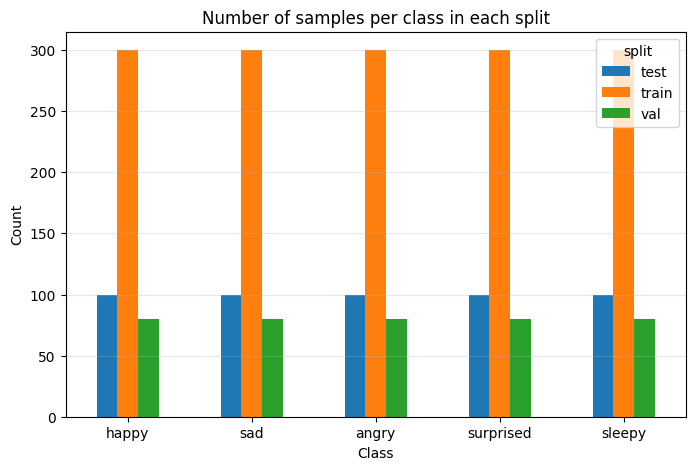

In [7]:
SPLIT_COUNTS = {
    "train": 300,
    "val": 80,
    "test": 100,
}

def build_records(split_name, class_names, counts_per_class, hard_mode=False, seed_offset=0):
    records = []
    label_to_idx = {name: i for i, name in enumerate(class_names)}
    for class_name in class_names:
        label_idx = label_to_idx[class_name]
        for i in range(counts_per_class):
            records.append({
                "split": split_name,
                "label_name": class_name,
                "label_idx": label_idx,
                "seed": seed_offset + 10_000 * label_idx + i,
                "hard_mode": hard_mode,
            })
    random.Random(SEED + seed_offset).shuffle(records)
    return records

# TODO:
train_records = build_records(
    split_name="train",
    class_names=CLASS_NAMES,
    counts_per_class=SPLIT_COUNTS["train"],
    hard_mode=False,
    seed_offset=0
)

val_records = build_records(
    split_name="val",
    class_names=CLASS_NAMES,
    counts_per_class=SPLIT_COUNTS["val"],
    hard_mode=False,
    seed_offset=1_000_000
)

test_records = build_records(
    split_name="test",
    class_names=CLASS_NAMES,
    counts_per_class=SPLIT_COUNTS["test"],
    hard_mode=False,
    seed_offset=2_000_000
)

all_records = pd.DataFrame(train_records + val_records + test_records)
display(all_records.head())

count_df = all_records.groupby(["split", "label_name"]).size().reset_index(name="count")
display(count_df)

# TODO: جدول یا نمودار تعداد نمونه‌ها
count_pivot = count_df.pivot(index="label_name", columns="split", values="count")
count_pivot = count_pivot.loc[CLASS_NAMES]

display(count_pivot)

count_pivot.plot(kind="bar", figsize=(8, 5))
plt.title("Number of samples per class in each split")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

## بخش ۳ — پیش‌پردازش و Data Augmentation

### صورت سؤال
1. برای داده‌های آموزشی یک pipeline مناسب از augmentation تعریف کنید.
2. برای داده‌های اعتبارسنجی و تست فقط پیش‌پردازش‌های ضروری را اعمال کنید.
3. توضیح دهید چرا در این مسئله این تبدیلات مناسب‌اند.

### پیشنهاد
برای train می‌توانید از موارد زیر استفاده کنید:
- `RandomRotation`
- `RandomResizedCrop`
- `ColorJitter`
- `RandomHorizontalFlip`

### خروجی مورد انتظار
- تعریف transformهای train / val / test
- نمایش یک نمونه تصویر قبل و بعد از augmentation

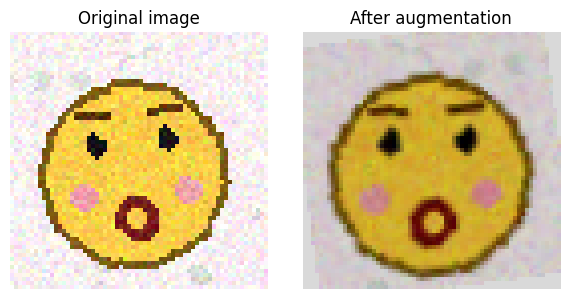

In [8]:
class Compose:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img):
        # TODO
        for transform in self.transforms:
            img = transform(img)
        return img


class Resize:
    def __init__(self, size):
        if isinstance(size, int):
            size = (size, size)
        self.size = size

    def __call__(self, img):
        # TODO
        return img.resize(self.size, Image.BILINEAR)


class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, img):
        # TODO
        if random.random() < self.p:
            return ImageOps.mirror(img)
        return img


class RandomRotation:
    def __init__(self, degrees):
        self.degrees = degrees

    def __call__(self, img):
        # TODO
        angle = random.uniform(-self.degrees, self.degrees)
        return img.rotate(
            angle,
            resample=Image.BILINEAR,
            fillcolor=(255, 255, 255)
        )


class RandomResizedCrop:
    def __init__(self, size, scale=(0.85, 1.0)):
        self.size = (size, size) if isinstance(size, int) else size
        self.scale = scale

    def __call__(self, img):
        # TODO
        w, h = img.size

        scale = random.uniform(self.scale[0], self.scale[1])
        crop_w = int(w * scale)
        crop_h = int(h * scale)

        if crop_w >= w:
            left = 0
        else:
            left = random.randint(0, w - crop_w)

        if crop_h >= h:
            top = 0
        else:
            top = random.randint(0, h - crop_h)

        img = img.crop((left, top, left + crop_w, top + crop_h))
        img = img.resize(self.size, Image.BILINEAR)
        return img


class ColorJitter:
    def __init__(self, brightness=0.0, contrast=0.0, saturation=0.0):
        self.brightness = brightness
        self.contrast = contrast
        self.saturation = saturation

    def __call__(self, img):
        # TODO
        if self.brightness > 0:
            factor = random.uniform(1 - self.brightness, 1 + self.brightness)
            img = ImageEnhance.Brightness(img).enhance(factor)

        if self.contrast > 0:
            factor = random.uniform(1 - self.contrast, 1 + self.contrast)
            img = ImageEnhance.Contrast(img).enhance(factor)

        if self.saturation > 0:
            factor = random.uniform(1 - self.saturation, 1 + self.saturation)
            img = ImageEnhance.Color(img).enhance(factor)

        return img


class ToTensorNormalize:
    def __init__(self, mean, std):
        self.mean = np.array(mean, dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array(std, dtype=np.float32).reshape(3, 1, 1)

    def __call__(self, img):
        # TODO
        img = img.convert("RGB")
        arr = np.array(img).astype(np.float32) / 255.0
        arr = arr.transpose(2, 0, 1)

        arr = (arr - self.mean) / self.std

        return torch.tensor(arr, dtype=torch.float32)


# TODO
train_transform = Compose([
    RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    RandomRotation(degrees=15),
    RandomHorizontalFlip(p=0.5),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ToTensorNormalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

eval_transform = Compose([
    Resize(IMG_SIZE),
    ToTensorNormalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])


def denormalize(t):
    t = t.clone().cpu()
    for c in range(3):
        t[c] = t[c] * 0.5 + 0.5
    return t.clamp(0, 1)


sample_img = draw_emoji("surprised", img_size=IMG_SIZE, seed=1234)
augmented = train_transform(sample_img)

# TODO: نمایش یک نمونه تصویر قبل و بعد
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(sample_img)
axes[0].set_title("Original image")
axes[0].axis("off")

aug_img = denormalize(augmented).permute(1, 2, 0).numpy()
axes[1].imshow(aug_img)
axes[1].set_title("After augmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## بخش ۴ — ساخت Dataset و DataLoader

### صورت سؤال
1. برای train / val / test سه DataLoader ایجاد کنید.
2. یک batch را نمایش دهید و shape داده‌ها و برچسب‌ها را چاپ کنید.

### خروجی مورد انتظار
- سه dataloader
- نمایش یک batch نمونه

In [9]:
class EmojiMoodDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = draw_emoji(
            rec["label_name"],
            img_size=IMG_SIZE,
            seed=rec["seed"],
            hard_mode=rec["hard_mode"],
        )
        if self.transform is not None:
            img = self.transform(img)
        label = rec["label_idx"]
        return img, label


# TODO
train_dataset = EmojiMoodDataset(train_records, transform=train_transform)
val_dataset   = EmojiMoodDataset(val_records, transform=eval_transform)
test_dataset  = EmojiMoodDataset(test_records, transform=eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 64, 64])
Batch label shape: torch.Size([64])


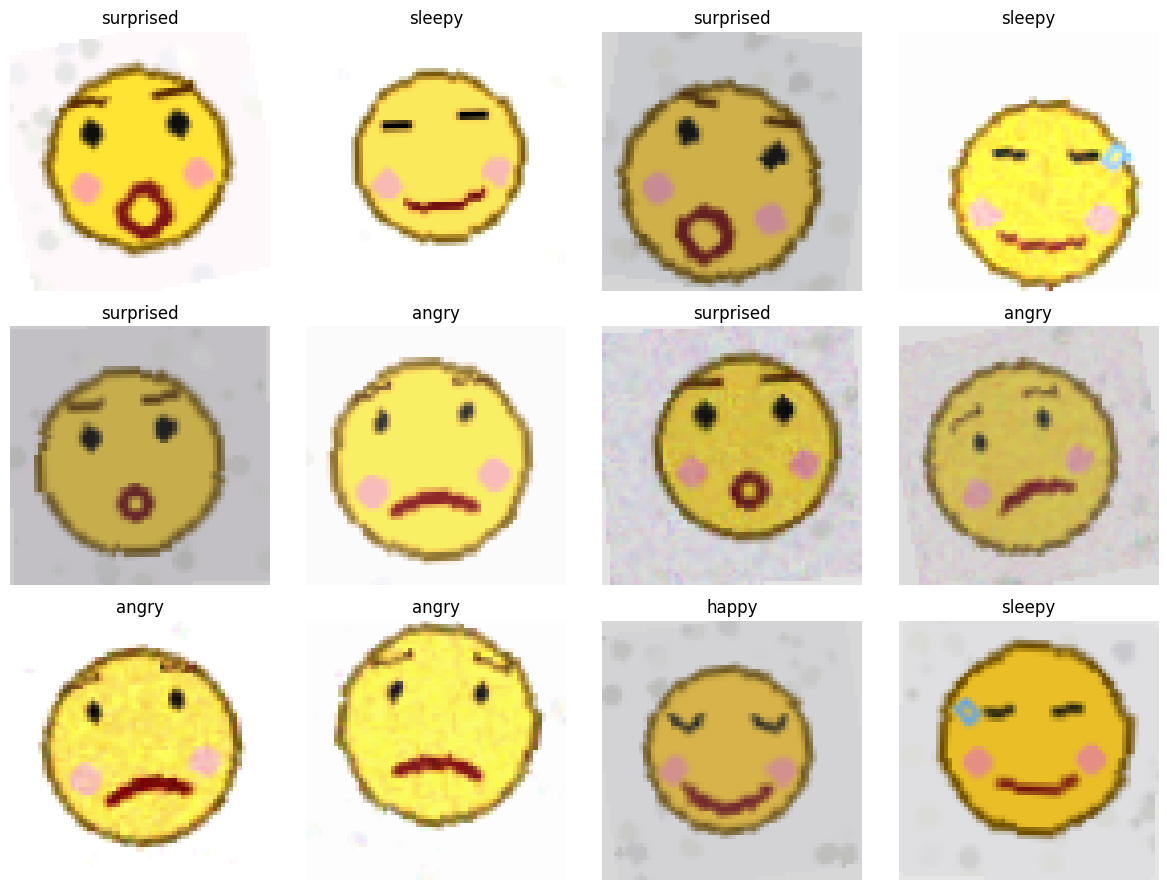

In [10]:
def show_batch(images, labels, class_names, max_items=12):
    # TODO
    n = min(max_items, images.shape[0])

    cols = 4
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = np.array(axes).reshape(-1)

    for i in range(n):
        img = denormalize(images[i]).permute(1, 2, 0).numpy()
        label_idx = labels[i].item()

        axes[i].imshow(img)
        axes[i].set_title(class_names[label_idx])
        axes[i].axis("off")

    for i in range(n, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()
show_batch(images, labels, CLASS_NAMES)

## بخش ۵ — طراحی CNN پایه

### صورت سؤال
یک CNN پایه از صفر طراحی کنید که:
1. حداقل 3 بلوک کانولوشنی داشته باشد.
2. در انتها برای طبقه‌بندی از fully connected layers استفاده کند.
3. برای جلوگیری از overfitting از dropout استفاده کند.

### کارهای لازم
- مدل را پیاده‌سازی کنید.
- summary ساده‌ای از تعداد پارامترها گزارش کنید.
- یک forward pass آزمایشی انجام دهید.

### خروجی مورد انتظار
- تعریف مدل
- تعداد پارامترهای قابل آموزش
- shape خروجی مدل برای یک batch نمونه

In [11]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        
        # TODO
        self.features = nn.Sequential(
            # Block 1: 3 x 64 x 64 -> 32 x 32 x 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 32 x 32 x 32 -> 64 x 16 x 16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 64 x 16 x 16 -> 128 x 8 x 8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(p=0.4),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # TODO
        x = self.features(x)
        x = self.classifier(x)
        
        return x


# TODO
baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(device)


def count_trainable_params(model):
    # TODO
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(baseline_model)
print(f"Trainable params: {count_trainable_params(baseline_model):,}")

# TODO: شکل خروجی مدل
images = images.to(device)

with torch.no_grad():
    outputs = baseline_model(images)

print("Input batch shape:", images.shape)
print("Output batch shape:", outputs.shape)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Drop

## بخش ۶ — توابع آموزش و ارزیابی

### صورت سؤال
توابع زیر را پیاده‌سازی کنید:
1. `train_one_epoch`
2. `evaluate_one_epoch`
3. یک حلقه‌ی آموزشی کامل که:
   - loss و accuracy را ذخیره کند
   - بهترین مدل را بر اساس validation loss نگه دارد

### نکته
در این تمرین از:
- `CrossEntropyLoss`
- بهینه‌ساز `Adam`

استفاده می‌کنیم.

### خروجی مورد انتظار
- توابع عمومی آموزش و ارزیابی

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    # TODO
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).long()

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size

        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
        total_samples += batch_size

    epoch_loss = total_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate_one_epoch(model, loader, criterion, device):
    # TODO
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).long()

        outputs = model(images)
        loss = criterion(outputs, labels)

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size

        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
        total_samples += batch_size

    epoch_loss = total_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    return epoch_loss, epoch_acc


def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=8,
    patience=3
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    best_state = deepcopy(model.state_dict())
    best_val_loss = float("inf")
    wait = 0

    for epoch in range(1, epochs + 1):
        # TODO: فاز آموزش و ارزیابی را انجام دهید
        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_acc = evaluate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )
        
        # TODO: خروجی توابع را در تاریخچه ثبت کنید
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping triggered.")
                break

    model.load_state_dict(best_state)
    return history

## بخش ۷ — آموزش مدل پایه

### صورت سؤال
1. criterion و optimizer را تعریف کنید.
2. مدل پایه را برای چند epoch آموزش دهید.
3. تاریخچه‌ی آموزش را ذخیره کنید.
4. در پایان، بهترین نسخه‌ی مدل را نگه دارید.

### خروجی مورد انتظار
- لاگ آموزش در هر epoch

In [13]:
# TODO
baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

baseline_history = fit_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=8,
    patience=3
)

Epoch 01 | train_loss=1.6542 train_acc=0.2900 | val_loss=1.3254 val_acc=0.5475
Epoch 02 | train_loss=0.9404 train_acc=0.6107 | val_loss=0.6008 val_acc=0.7150
Epoch 03 | train_loss=0.4569 train_acc=0.7973 | val_loss=0.3462 val_acc=0.8550
Epoch 04 | train_loss=0.3518 train_acc=0.8360 | val_loss=0.3224 val_acc=0.8475
Epoch 05 | train_loss=0.2373 train_acc=0.9027 | val_loss=0.2516 val_acc=0.8925
Epoch 06 | train_loss=0.2101 train_acc=0.9113 | val_loss=0.1471 val_acc=0.9450
Epoch 07 | train_loss=0.1744 train_acc=0.9307 | val_loss=0.0793 val_acc=0.9825
Epoch 08 | train_loss=0.1152 train_acc=0.9627 | val_loss=0.0411 val_acc=0.9850


## بخش ۸ — رسم نمودارهای آموزش

### صورت سؤال
1. نمودار `train/val loss` را رسم کنید.
2. نمودار `train/val accuracy` را رسم کنید.
3. توضیح دهید آیا نشانه‌ای از overfitting یا underfitting مشاهده می‌شود یا خیر.

### خروجی مورد انتظار
- دو نمودار

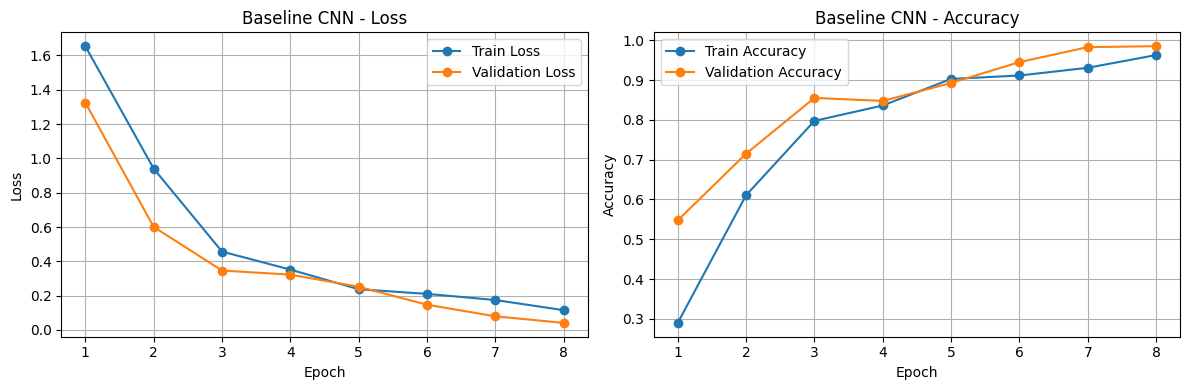

In [14]:
def plot_history(history, title_prefix="Model"):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # TODO
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train Loss")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
    axes[0].set_title(f"{title_prefix} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
    axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
    axes[1].set_title(f"{title_prefix} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

plot_history(baseline_history, title_prefix="Baseline CNN")

## بخش ۹ — ارزیابی نهایی روی داده‌ی تست

### صورت سؤال
1. مدل را روی test set ارزیابی کنید.
2. معیارهای زیر را گزارش کنید:
   - Accuracy
   - Precision (macro)
   - Recall (macro)
   - F1-score (macro)
3. یک **Confusion Matrix** رسم کنید.
4. نتیجه را تفسیر کنید: کدام کلاس‌ها بیشتر با هم اشتباه می‌شوند؟

### خروجی مورد انتظار
- metricها
- confusion matrix
- classification report

Baseline Test Accuracy : 0.9760
Baseline Test Precision: 0.9766
Baseline Test Recall   : 0.9760
Baseline Test F1-score : 0.9760

Classification report:
              precision    recall  f1-score   support

       happy       1.00      1.00      1.00       100
         sad       0.92      0.97      0.94       100
       angry       0.97      0.91      0.94       100
   surprised       1.00      1.00      1.00       100
      sleepy       1.00      1.00      1.00       100

    accuracy                           0.98       500
   macro avg       0.98      0.98      0.98       500
weighted avg       0.98      0.98      0.98       500



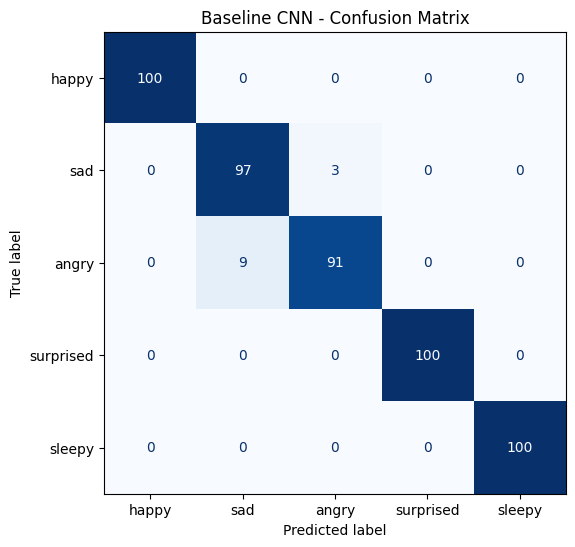

In [16]:
@torch.no_grad()
def predict_loader(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    for images, targets in loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        all_probs.append(probs.cpu())
        all_preds.append(preds.cpu())
        all_targets.append(targets)

    all_probs = torch.cat(all_probs).numpy()
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    return all_probs, all_preds, all_targets


# TODO
baseline_probs, baseline_preds, test_targets = predict_loader(
    baseline_model,
    test_loader,
    device
)

baseline_acc = accuracy_score(test_targets, baseline_preds)

baseline_prec, baseline_rec, baseline_f1, _ = precision_recall_fscore_support(
    test_targets,
    baseline_preds,
    average="macro",
    zero_division=0
)

print(f"Baseline Test Accuracy : {baseline_acc:.4f}")
print(f"Baseline Test Precision: {baseline_prec:.4f}")
print(f"Baseline Test Recall   : {baseline_rec:.4f}")
print(f"Baseline Test F1-score : {baseline_f1:.4f}")

print("\nClassification report:")
print(
    classification_report(
        test_targets,
        baseline_preds,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

cm = confusion_matrix(test_targets, baseline_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Baseline CNN - Confusion Matrix")
plt.show()

<div dir="rtl" align="right">

### تحلیل نتایج مدل پایه روی داده‌ی تست

در این بخش مدل `BaselineCNN` روی داده‌های تست ارزیابی شد. نتیجه کلی مدل خیلی خوب است، چون accuracy روی test برابر با `0.9760` شده است. یعنی مدل از ۵۰۰ تصویر تست، تقریباً ۹۷.۶ درصد را درست تشخیص داده است. مقدارهای precision، recall و F1-score هم تقریباً همگی نزدیک به `0.98` هستند، پس عملکرد مدل فقط روی یک معیار خوب نیست و از چند جهت نتیجه قابل قبولی دارد.

در گزارش classification report می‌بینیم که مدل برای کلاس‌های `happy`، `surprised` و `sleepy` عملکرد کامل داشته است. برای این سه کلاس مقدار precision، recall و F1-score برابر با `1.00` شده، یعنی مدل تقریباً هیچ اشتباهی در تشخیص آن‌ها نداشته است. به نظر می‌رسد این کلاس‌ها از نظر ظاهری ویژگی‌های واضح‌تری دارند؛ مثلاً `surprised` معمولاً دهان باز و مشخص دارد، `happy` حالت دهان متفاوتی دارد و `sleepy` هم از روی چشم‌ها راحت‌تر قابل تشخیص است.

اما بیشترین خطاها بین دو کلاس `sad` و `angry` اتفاق افتاده‌اند. برای کلاس `sad` مقدار recall برابر با `0.97` است، یعنی بیشتر نمونه‌های sad درست پیدا شده‌اند، ولی precision آن `0.92` است. این یعنی بعضی نمونه‌هایی که واقعاً sad نبوده‌اند، به اشتباه sad پیش‌بینی شده‌اند. از طرف دیگر، برای کلاس `angry` مقدار precision برابر با `0.97` ولی recall برابر با `0.91` است. یعنی وقتی مدل چیزی را angry تشخیص داده، معمولاً درست بوده، اما تعدادی از نمونه‌های واقعی angry را از دست داده و احتمالاً آن‌ها را sad تشخیص داده است.

از نظر بصری هم این اشتباه قابل درک است. کلاس‌های `sad` و `angry` هر دو معمولاً دهان رو به پایین دارند و حالت کلی صورتشان تا حدی شبیه هم است. تفاوت اصلی angry بیشتر در حالت ابروها و چشم‌هاست. اگر تصویر کمی نویز داشته باشد یا جزئیات ابروها واضح نباشد، مدل ممکن است بیشتر به شکل دهان توجه کند و angry را با sad اشتباه بگیرد.

در کل، مدل پایه عملکرد خیلی خوبی داشته و روی بیشتر کلاس‌ها تقریباً بدون خطا عمل کرده است. تنها نقطه ضعف اصلی آن تفکیک بین `sad` و `angry` است، که آن هم به خاطر شباهت ظاهری این دو حالت چهره طبیعی به نظر می‌رسد.

</div>

## بخش ۱۰ — تحلیل خطاها

### صورت سؤال
1. چند نمونه از تصاویر اشتباه‌طبقه‌بندی‌شده را نمایش دهید.
2. برای هر نمونه، برچسب واقعی و برچسب پیش‌بینی‌شده را بنویسید.
3. تلاش کنید برای خطاها توضیح بصری بدهید؛ مثلاً:
   - چرخش زیاد
   - نویز
   - شباهت بین mouth patternها
   - occlusion

### خروجی مورد انتظار
- چند تصویر misclassified
- تحلیل کیفی

Number of mistakes: 12 / 500


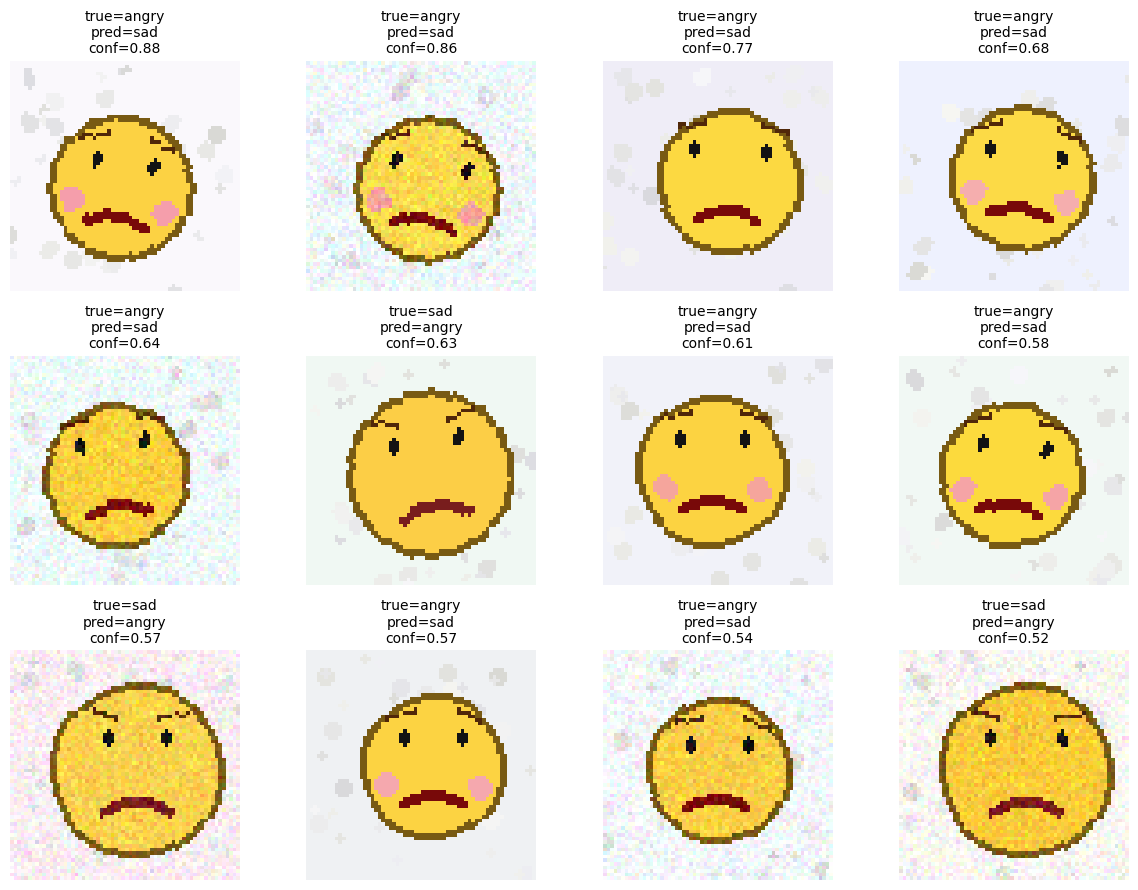

In [17]:
@torch.no_grad()
def collect_predictions_with_images(model, dataset, device, max_items=None):
    model.eval()
    items = []
    total = len(dataset) if max_items is None else min(len(dataset), max_items)

    for idx in range(total):
        # TODO
        image, label = dataset[idx]

        input_image = image.unsqueeze(0).to(device)
        output = model(input_image)

        prob = torch.softmax(output, dim=1).squeeze(0).cpu()
        pred = int(prob.argmax().item())

        items.append({
            "image": image,
            "label": int(label),
            "pred": pred,
            "confidence": float(prob[pred].item()),
        })
    return items


# TODO
test_items = collect_predictions_with_images(
    baseline_model,
    test_dataset,
    device
)

mistakes = [
    item for item in test_items
    if item["label"] != item["pred"]
]

mistakes = sorted(mistakes, key=lambda x: x["confidence"], reverse=True)

print(f"Number of mistakes: {len(mistakes)} / {len(test_items)}")

n_show = min(12, len(mistakes))
if n_show > 0:
    cols = 4
    rows = math.ceil(n_show / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(rows, cols)

    for ax in axes.ravel():
        ax.axis("off")

    for i in range(n_show):
        item = mistakes[i]
        img = np.transpose(denormalize(item["image"]).numpy(), (1, 2, 0))
        ax = axes.ravel()[i]
        ax.imshow(img)
        ax.set_title(
            f"true={CLASS_NAMES[item['label']]}\npred={CLASS_NAMES[item['pred']]}\nconf={item['confidence']:.2f}",
            fontsize=10
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Great! No mistakes found in the displayed set.")

<div dir="rtl" align="right">

### تحلیل کیفی خطاهای مدل

در این بخش چند نمونه از تصویرهایی که مدل اشتباه تشخیص داده، نمایش داده شده‌اند. چیزی که در این نمونه‌ها خیلی مشخص است این است که بیشتر خطاها بین دو کلاس `angry` و `sad` اتفاق افتاده‌اند. یعنی مدل در بسیاری از موارد ایموجی‌های angry را به عنوان sad تشخیص داده و در چند نمونه هم برعکس، sad را angry پیش‌بینی کرده است.

به نظر من دلیل اصلی این اشتباه، شباهت زیاد حالت دهان در این دو کلاس است. در هر دو حالت، دهان حالت رو به پایین دارد و همین باعث می‌شود مدل نتواند همیشه تفاوت بین ناراحتی و عصبانیت را دقیق تشخیص دهد. تفاوت اصلی angry معمولاً بیشتر در حالت ابروها و چشم‌هاست، اما اگر تصویر کمی نویز داشته باشد یا صورت کمی جابه‌جا و تار شود، این تفاوت‌ها کمتر واضح می‌شوند.

در بعضی نمونه‌ها هم نویز تصویر زیاد است و جزئیات صورت خیلی تمیز دیده نمی‌شود. مخصوصاً در چند تصویر، بافت نویزی روی کل صورت افتاده و باعث شده خطوط دهان و ابروها کمتر مشخص باشند. این موضوع احتمالاً باعث شده مدل بیشتر به شکل کلی دهان توجه کند و angry را با sad اشتباه بگیرد.

همچنین confidence مدل در بعضی خطاها نسبتاً بالاست؛ مثلاً چند مورد با اطمینان حدود ۰.۸ یا ۰.۸۶ اشتباه پیش‌بینی شده‌اند. این نشان می‌دهد مدل فقط شک نکرده، بلکه واقعاً بعضی الگوهای angry را شبیه sad یاد گرفته است. این نوع خطاها مهم‌تر هستند، چون نشان می‌دهند مدل در جدا کردن این دو کلاس هنوز مشکل دارد.

در کل، به نظر می‌رسد مدل برای کلاس‌هایی که تفاوت ظاهری واضح‌تری دارند بهتر عمل می‌کند، اما بین کلاس‌های شبیه‌تر مثل `angry` و `sad` بیشتر اشتباه می‌کند. برای بهتر شدن مدل، می‌شود نمونه‌های بیشتری از این دو کلاس تولید کرد، augmentation را کمی کنترل‌شده‌تر کرد، یا مدل را طوری قوی‌تر کرد که بیشتر به جزئیات ابرو و چشم‌ها توجه کند، نه فقط شکل دهان.

</div>


## بخش ۱۱ — مشاهده‌ی feature mapها

### صورت سؤال
برای یکی از تصاویر تست:
1. خروجی اولین بلوک کانولوشنی را استخراج کنید.
2. چند feature map را نمایش دهید.
3. توضیح دهید که این feature mapها احتمالاً چه نوع الگوهایی را شکار می‌کنند.

### خروجی مورد انتظار
- تصویر ورودی
- چند feature map

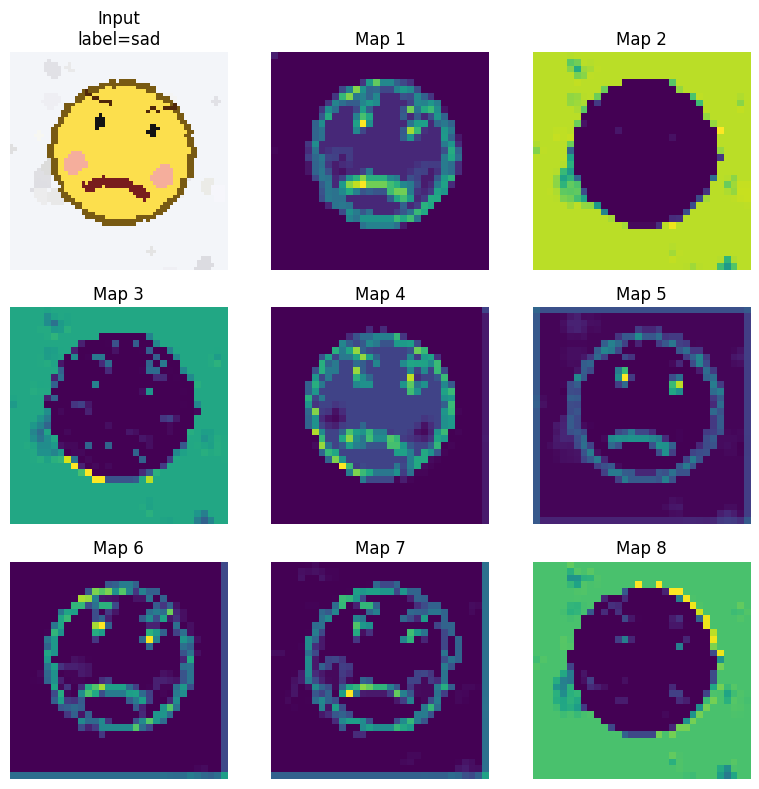

In [18]:
@torch.no_grad()
def show_feature_maps(model, dataset, sample_idx=0, n_maps=8):
    model.eval()
    image, label = dataset[sample_idx]
    x = image.unsqueeze(0).to(device)

    # TODO:
    first_block = model.features[:4]
    fmap = first_block(x).squeeze(0).cpu()

    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    axes = axes.ravel()

    axes[0].imshow(np.transpose(denormalize(image).numpy(), (1, 2, 0)))
    axes[0].set_title(f"Input\nlabel={CLASS_NAMES[label]}")
    axes[0].axis("off")

    for i in range(1, min(n_maps + 1, 9)):
        axes[i].imshow(fmap[i - 1], cmap="viridis")
        axes[i].set_title(f"Map {i}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

show_feature_maps(baseline_model, test_dataset, sample_idx=3, n_maps=8)

## بخش ۱۲ — مدل بهبود‌یافته

### صورت سؤال
اکنون یک مدل بهتر طراحی کنید که نسبت به مدل پایه، **پایدارتر** و **قابل‌تعمیم‌تر** باشد.

### پیشنهادها
- استفاده از `BatchNorm`
- استفاده از `AdaptiveAvgPool2d`
- استفاده از dropout بیشتر
- عمیق‌تر کردن مدل
- استفاده از optimizer و weight decay مناسب

### کارهای لازم
1. مدل جدید را پیاده‌سازی کنید.
2. آن را آموزش دهید.
3. عملکردش را با مدل پایه مقایسه کنید.

### خروجی مورد انتظار
- تعریف مدل جدید
- لاگ آموزش
- مقایسه‌ی metricها

In [19]:
class BetterCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # TODO
        self.features = nn.Sequential(
            # Block 1: 3 x 64 x 64 -> 32 x 32 x 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.10),

            # Block 2: 32 x 32 x 32 -> 64 x 16 x 16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.15),

            # Block 3: 64 x 16 x 16 -> 128 x 8 x 8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.20),

            # Block 4: 128 x 8 x 8 -> 256 x 4 x 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 256 x 4 x 4 -> 256 x 1 x 1
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=0.50),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # TODO
        x = self.features(x)
        x = self.classifier(x)
        
        return x


better_model = BetterCNN(num_classes=NUM_CLASSES).to(device)

print(better_model)
print(f"Trainable params: {count_trainable_params(better_model):,}")

BetterCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout2d(p=0.15, in

Epoch 01 | train_loss=1.4039 train_acc=0.3813 | val_loss=1.6602 val_acc=0.2000
Epoch 02 | train_loss=0.8661 train_acc=0.6887 | val_loss=0.3926 val_acc=0.8750
Epoch 03 | train_loss=0.4661 train_acc=0.8160 | val_loss=0.2279 val_acc=0.9375
Epoch 04 | train_loss=0.3189 train_acc=0.8733 | val_loss=0.1619 val_acc=0.9325
Epoch 05 | train_loss=0.2607 train_acc=0.8887 | val_loss=0.1516 val_acc=0.9425
Epoch 06 | train_loss=0.2245 train_acc=0.9027 | val_loss=0.1548 val_acc=0.9325
Epoch 07 | train_loss=0.1937 train_acc=0.9207 | val_loss=0.1344 val_acc=0.9325
Epoch 08 | train_loss=0.1824 train_acc=0.9253 | val_loss=0.1229 val_acc=0.9425
Epoch 09 | train_loss=0.1671 train_acc=0.9273 | val_loss=0.1605 val_acc=0.9325
Epoch 10 | train_loss=0.1854 train_acc=0.9213 | val_loss=0.1603 val_acc=0.9250


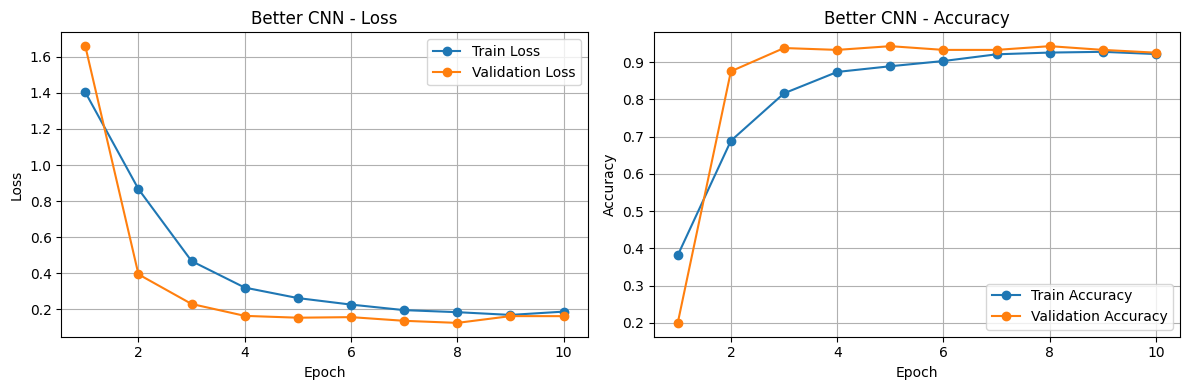

In [20]:
# TODO
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    better_model.parameters(),
    lr=8e-4,
    weight_decay=1e-4
)

better_history = fit_model(
    better_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=10,
    patience=4,
)

plot_history(better_history, title_prefix="Better CNN")

,model,accuracy,precision_macro,recall_macro,f1_macro,params
0,BaselineCNN,0.976,0.976636,0.976,0.975978,2207877
1,BetterCNN,0.946,0.957480,0.946,0.944998,617125


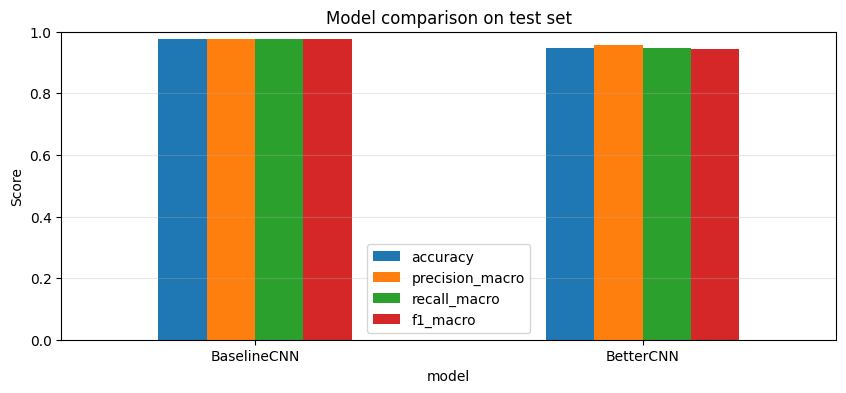

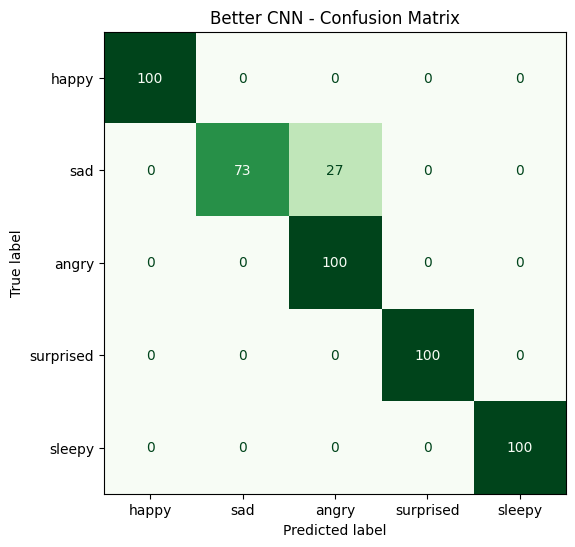

In [21]:
# TODO
better_probs, better_preds, _ = predict_loader(
    better_model,
    test_loader,
    device
)

# TODO
better_acc = accuracy_score(test_targets, better_preds)

better_prec, better_rec, better_f1, _ = precision_recall_fscore_support(
    test_targets,
    better_preds,
    average="macro",
    zero_division=0
)

comparison_df = pd.DataFrame([
    {
        "model": "BaselineCNN",
        "accuracy": baseline_acc,
        "precision_macro": baseline_prec,
        "recall_macro": baseline_rec,
        "f1_macro": baseline_f1,
        "params": count_trainable_params(baseline_model),
    },
    {
        "model": "BetterCNN",
        "accuracy": better_acc,
        "precision_macro": better_prec,
        "recall_macro": better_rec,
        "f1_macro": better_f1,
        "params": count_trainable_params(better_model),
    },
])

display(comparison_df)

comparison_df.set_index("model")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar", figsize=(10, 4)
)
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Model comparison on test set")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

cm_better = confusion_matrix(test_targets, better_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_better, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Greens", values_format="d", colorbar=False)
plt.title("Better CNN - Confusion Matrix")
plt.show()

## بخش ۱۳ — جمع‌بندی و پرسش‌های تحلیلی

### صورت سؤال
به پرسش‌های زیر پاسخ دهید:

1. آیا augmentation باعث بهتر شدن عملکرد مدل شد؟ چرا؟
2. کدام کلاس‌ها بیشتر با هم اشتباه شدند؟ دلیل بصری آن چیست؟
3. بین مدل پایه و مدل بهتر، کدام تغییرات بیشترین اثر را داشتند؟
4. آیا افزایش تعداد پارامترها همیشه به بهبود نتیجه منجر شد؟
5. اگر بخواهید این پروژه را سخت‌تر کنید، چه تغییری می‌دهید؟

### چند ایده برای بخش امتیازی
- ساخت یک **harder test set** با occlusion شدیدتر
- مقایسه‌ی optimizerهای `Adam` و `RMSprop`
- اضافه کردن **label smoothing**
- پیاده‌سازی **Grad-CAM** برای توضیح تصمیم مدل
- تبدیل مسئله از 5 کلاس به 7 کلاس با اضافه کردن `cool` و `confused`



<div dir="rtl" align="right">

### پاسخ به پرسش‌ها

#### ۱. آیا augmentation باعث بهتر شدن عملکرد مدل شد؟ چرا؟

به نظر من augmentation در این تمرین مفید بود، چون تصاویر ایموجی‌ها همیشه دقیقاً در یک حالت ثابت نبودند. در نمونه‌ای که قبل و بعد از augmentation نمایش داده شد، تصویر بعد از augmentation کمی تغییر اندازه، تغییر رنگ، چرخش/تغییر ظاهری و حالت نرم‌تر پیدا کرده بود. این باعث می‌شود مدل فقط شکل کاملاً تمیز و ثابت ایموجی را حفظ نکند، بلکه یاد بگیرد اگر تصویر کمی نویزی، جابه‌جا یا متفاوت بود هم بتواند کلاس را تشخیص دهد.

در نتایج مدل پایه هم می‌بینیم که validation accuracy خیلی خوب بالا رفته و در نهایت به حدود `0.985` رسیده است. همچنین accuracy روی test برابر `0.976` شده که نشان می‌دهد مدل فقط روی train خوب عمل نکرده، بلکه روی داده‌های جدید هم عملکرد خوبی داشته است. به همین دلیل می‌توان گفت augmentation به بهتر شدن تعمیم‌پذیری مدل کمک کرده است.

البته augmentation اگر خیلی شدید باشد ممکن است بعضی ویژگی‌های مهم صورت مثل دهان یا ابرو را خراب کند و باعث سخت‌تر شدن تشخیص شود. ولی در اینجا مقدار augmentation به نظر مناسب بوده، چون مدل توانسته عملکرد خوبی روی validation و test داشته باشد.

---

#### ۲. کدام کلاس‌ها بیشتر با هم اشتباه شدند؟ دلیل بصری آن چیست؟

طبق classification report، بیشتر خطاها بین کلاس‌های `sad` و `angry` اتفاق افتاده‌اند. برای کلاس‌های `happy`، `surprised` و `sleepy` تقریباً عملکرد کامل بوده و precision و recall آن‌ها برابر با `1.00` شده است. اما برای `sad` و `angry` مقدار F1-score حدود `0.94` است که نشان می‌دهد مدل در این دو کلاس بیشتر اشتباه کرده است.

از نظر بصری این موضوع قابل توضیح است. کلاس‌های `sad` و `angry` هر دو معمولاً دهان رو به پایین دارند و حالت کلی چهره‌شان شبیه هم است. تفاوت اصلی آن‌ها بیشتر در ابروها و حالت چشم‌هاست. وقتی تصویر کمی نویز داشته باشد، یا augmentation باعث تغییر زاویه و رنگ شود، این تفاوت‌های ظریف کمتر مشخص می‌شوند و مدل ممکن است angry را sad یا sad را angry تشخیص دهد.

در تحلیل خطاها هم همین موضوع دیده شد؛ بیشتر نمونه‌های اشتباه مربوط به جابه‌جایی بین `angry` و `sad` بودند، و حتی بعضی از آن‌ها با confidence نسبتاً بالا اشتباه پیش‌بینی شده بودند. این یعنی مدل واقعاً در جدا کردن این دو الگو هنوز کمی مشکل دارد.

---

#### ۳. بین مدل پایه و مدل بهتر، کدام تغییرات بیشترین اثر را داشتند؟

مدل بهتر از نظر طراحی معماری تغییرات خوبی داشت؛ مثلاً عمیق‌تر شد، از `BatchNorm` بیشتر استفاده کرد، `Dropout2d` داشت و با `AdaptiveAvgPool2d` تعداد پارامترها را کمتر کرد. به نظرم مهم‌ترین تغییر در مدل بهتر همین استفاده از `AdaptiveAvgPool2d` بود، چون باعث شد مدل به جای flatten کردن یک feature map بزرگ، یک نمایش فشرده‌تر بسازد. به همین دلیل تعداد پارامترهای مدل بهتر خیلی کمتر شد.

مدل پایه حدود `2,207,877` پارامتر داشت، ولی مدل بهتر فقط حدود `617,125` پارامتر داشت. یعنی مدل بهتر از نظر تعداد پارامترها سبک‌تر و منظم‌تر بود. این از نظر طراحی مدل یک نکته مثبت است، چون مدل کوچک‌تر معمولاً احتمال overfitting کمتری دارد و سریع‌تر هم آموزش می‌بیند.

اما از نظر نتیجه نهایی، مدل بهتر در این اجرا از مدل پایه بهتر نشد. مدل پایه accuracy حدود `0.976` گرفت، ولی مدل بهتر accuracy حدود `0.946` داشت. بنابراین در این آزمایش خاص، با اینکه طراحی مدل بهتر از نظر معماری تمیزتر و سبک‌تر بود، ولی بهترین عملکرد عددی را مدل پایه داد.

---

#### ۴. آیا افزایش تعداد پارامترها همیشه به بهبود نتیجه منجر شد؟

نه، افزایش تعداد پارامترها همیشه به معنی بهتر شدن نتیجه نیست. در این تمرین اتفاقاً مدل پایه پارامترهای خیلی بیشتری داشت و نتیجه بهتری گرفت، اما این را نمی‌شود به صورت کلی یک قانون دانست. ممکن است یک مدل بزرگ‌تر روی یک دیتاست کوچک خوب جواب بدهد، ولی در حالت دیگر دچار overfitting شود.

مدل بهتر با وجود اینکه پارامترهای کمتری داشت، از نظر معماری منظم‌تر بود، اما در این اجرا accuracy پایین‌تری گرفت. این نشان می‌دهد که عملکرد مدل فقط به تعداد پارامترها وابسته نیست. عواملی مثل نوع معماری، learning rate، مقدار dropout، تعداد epochها، optimizer، شدت augmentation و حتی سختی کلاس‌ها هم روی نتیجه اثر دارند.

پس به نظر من مهم‌تر از زیاد کردن پارامترها، این است که مدل متناسب با مسئله طراحی شود. گاهی یک مدل کوچک‌تر ولی خوب تنظیم‌شده می‌تواند بهتر از یک مدل بزرگ‌تر عمل کند.

---

#### ۵. اگر بخواهید این پروژه را سخت‌تر کنید، چه تغییری می‌دهید؟

برای سخت‌تر کردن پروژه، من چند تغییر پیشنهاد می‌دهم. اولین تغییر این است که حالت `hard_mode` را برای داده‌ها فعال کنیم تا تصاویر نویزی‌تر، چرخیده‌تر یا مبهم‌تر شوند. این باعث می‌شود مدل مجبور شود ویژگی‌های قوی‌تر و مقاوم‌تری یاد بگیرد.

تغییر دوم این است که شباهت بین کلاس‌ها را بیشتر کنیم. مثلاً برای کلاس‌های `sad` و `angry` حالت دهان را شبیه‌تر طراحی کنیم و تفاوت را فقط در ابروها یا چشم‌ها بگذاریم. در این حالت مدل باید روی جزئیات ظریف‌تر تمرکز کند.

تغییر سوم می‌تواند اضافه کردن occlusion باشد؛ مثلاً بخشی از صورت یا دهان پوشانده شود. این کار باعث می‌شود مسئله به حالت واقعی‌تری نزدیک شود، چون در داده‌های واقعی همیشه تصویر کامل و تمیز نیست.

همچنین می‌توان تعداد کلاس‌ها را بیشتر کرد، مثلاً کلاس‌هایی مثل `confused`، `neutral` یا `fearful` اضافه کرد. این کلاس‌ها از نظر ظاهری ممکن است به کلاس‌های فعلی نزدیک باشند و تشخیص را سخت‌تر کنند.

در کل، برای سخت‌تر کردن پروژه باید داده‌ها را از حالت ساده و تمیز خارج کنیم و آن‌ها را به تصاویر واقعی‌تر، نویزی‌تر و مبهم‌تر نزدیک کنیم.

</div>